# 6. Evaluación final en la prueba

La prueba es el día 30 y se usa una sola vez, en `scripts/07_final_test.py`. Las decisiones ya estaban tomadas: el umbral
de cada modelo se fijó en validación maximizando F1. Este capítulo responde P3.

| Modelo | Entorno | Datos de entrenamiento | Semillas |
|---|---|---|---|
| MLP `(100,)`, hash12 | scikit-learn | 10 M | 5 |
| SGD logístico, hash12 | scikit-learn | 10 M | 5 |
| HistGradientBoosting, target | scikit-learn | 10 M | 5 |
| MLP `[516, 128, 64, 2]`, hash 2^9 | PySpark | 1 M | 5 |
| MLP `[27, 50, 2]`, frecuencia | PySpark | 32,4 M | 1 |
| Regresión logística, hash12 | PySpark | 32,4 M | 1 |
| GBT, frecuencia y StringIndexer | PySpark | 32,4 M | 1 |

In [1]:
import sys, json
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from ctr.plots import C, style, es
from ctr.config import RES
style()
pd.set_option("display.max_columns", 30)
ST = RES / "stats"
NOM = {"sklearn_mlp": "sklearn MLP", "sklearn_sgd": "sklearn SGD", "sklearn_hgb": "sklearn HGB", "spark_mlp_hash9": "Spark MLP hash",
       "spark_mlp_freq": "Spark MLP frec.", "spark_lr_hash12": "Spark LR", "spark_gbt_gbt": "Spark GBT"}
COL = dict(zip(NOM, [C["azul"], C["aqua"], C["violeta"], C["naranja"], C["amarillo"], C["magenta"], C["rojo"]]))
r = pd.read_csv(ST / "test_resumen.csv"); r["m"] = r.modelo.map(NOM)
cur = json.load(open(ST / "curvas.json"))

## 6.1 Tabla de métricas

Media entre semillas. Los modelos con una sola corrida no tienen desviación ni intervalo t.

In [2]:
p = r.pivot(index="m", columns="metrica", values="media")[["auc", "pr_auc", "logloss", "brier", "ece", "accuracy", "precision", "recall", "f1"]]
p.columns = ["ROC AUC", "PR AUC", "Log loss", "Brier", "ECE", "Exactitud", "Precisión", "Recall", "F1"]
p.sort_values("ROC AUC", ascending=False).round(4)

,ROC AUC,PR AUC,Log loss,Brier,ECE,Exactitud,Precisión,Recall,F1
m,,,,,,,,,
sklearn HGB,0.7332,0.3615,0.4032,0.1259,0.0123,0.6768,0.2955,0.6564,0.4074
Spark LR,0.7255,0.3487,0.4082,0.1271,0.0103,0.6879,0.2994,0.6297,0.4059
sklearn SGD,0.7214,0.3436,0.4110,0.1278,0.0148,0.6856,0.2967,0.6251,0.4023
sklearn MLP,0.7173,0.3502,0.4139,0.1290,0.0293,0.6993,0.3001,0.5819,0.3958
Spark GBT,0.6984,0.3236,0.4223,0.1306,0.0255,0.6500,0.2728,0.6412,0.3828
Spark MLP hash,0.6979,0.3157,0.4200,0.1306,0.0145,0.6879,0.2867,0.5669,0.3808
Spark MLP frec.,0.6394,0.2754,0.4380,0.1355,0.0218,0.5253,0.2210,0.7148,0.3377


In [3]:
a = r[r.metrica == "auc"][["m", "media", "sd", "lo", "hi", "semillas"]].sort_values("media", ascending=False).round(4)
b = pd.read_csv(ST / "bootstrap.csv"); b = b[b.metrica == "auc"].assign(m=lambda d: d.modelo.map(NOM)).set_index("m")
a["boot_lo"], a["boot_hi"] = a.m.map(b.lo).round(4), a.m.map(b.hi).round(4)
a.rename(columns={"m": "Modelo", "media": "AUC media", "sd": "Desv.", "lo": "IC t bajo", "hi": "IC t alto", "boot_lo": "Boot. bajo", "boot_hi": "Boot. alto"}).set_index("Modelo")

,AUC media,Desv.,IC t bajo,IC t alto,semillas,Boot. bajo,Boot. alto
Modelo,,,,,,,
sklearn HGB,0.7332,0.0009,0.7321,0.7343,5,0.7322,0.7346
Spark LR,0.7255,0.0000,0.7255,0.7255,1,0.7241,0.7267
sklearn SGD,0.7214,0.0028,0.7179,0.7248,5,0.7198,0.7222
sklearn MLP,0.7173,0.0065,0.7092,0.7253,5,0.7223,0.7247
Spark GBT,0.6984,0.0000,0.6984,0.6984,1,0.6970,0.6998
Spark MLP hash,0.6979,0.0000,0.6979,0.6979,1,0.6964,0.6993
Spark MLP frec.,0.6394,0.0000,0.6394,0.6394,1,0.6379,0.6409


El intervalo t mide variación por semilla. El bootstrap mide variación por muestreo de filas de la prueba: 200 réplicas de
1 millón de filas, para una semilla de referencia.

## 6.2 Curvas ROC y PR

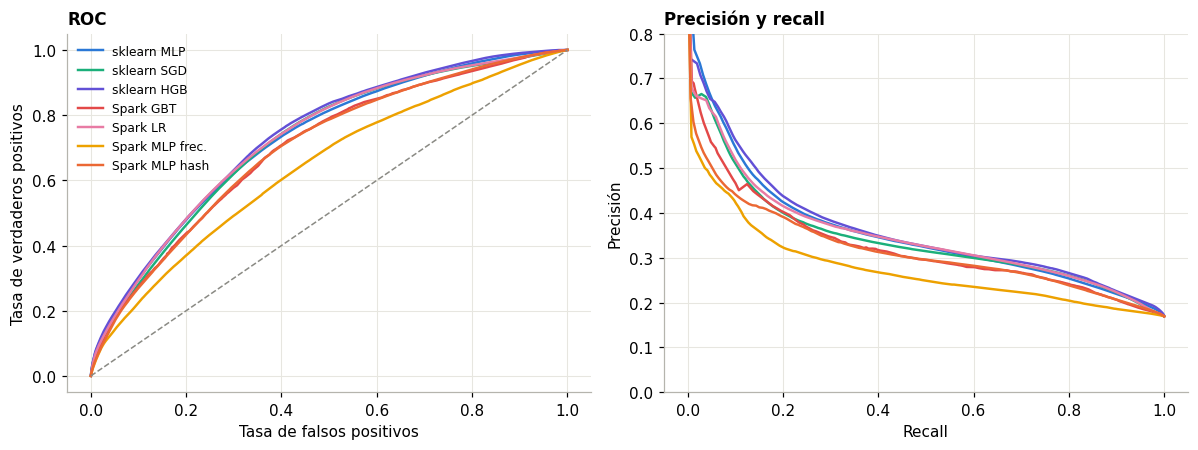

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for k, c in cur.items():
    ax[0].plot(c["fpr"], c["tpr"], color=COL[k], lw=1.6, label=NOM[k])
    ax[1].plot(c["rc"], c["pr"], color=COL[k], lw=1.6, label=NOM[k])
ax[0].plot([0, 1], [0, 1], color=C["gris"], lw=1, ls="--")
ax[0].set(title="ROC", xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos"); ax[0].legend(fontsize=8)
ax[1].set(title="Precisión y recall", xlabel="Recall", ylabel="Precisión", ylim=(0, .8))
plt.tight_layout(); plt.show()

## 6.3 Calibración

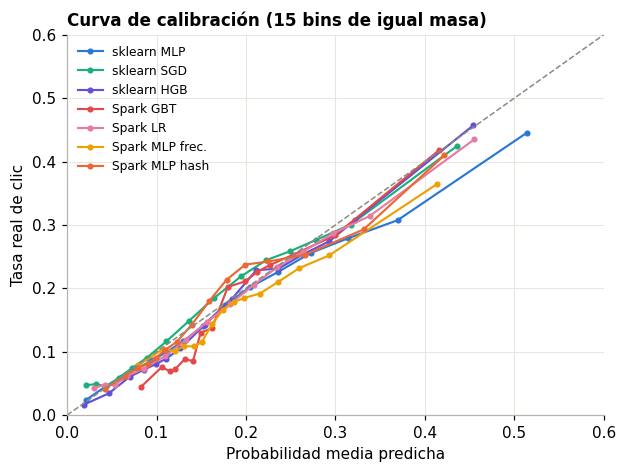

In [5]:
fig, ax = plt.subplots(figsize=(5.8, 4.4))
for k, c in cur.items():
    ax.plot(c["cal_p"], c["cal_y"], color=COL[k], marker="o", ms=3, lw=1.4, label=NOM[k])
ax.plot([0, .6], [0, .6], color=C["gris"], ls="--", lw=1)
ax.set(title="Curva de calibración (15 bins de igual masa)", xlabel="Probabilidad media predicha", ylabel="Tasa real de clic", xlim=(0, .6), ylim=(0, .6)); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 6.4 Utilidad de negocio: lift y ganancia acumulada

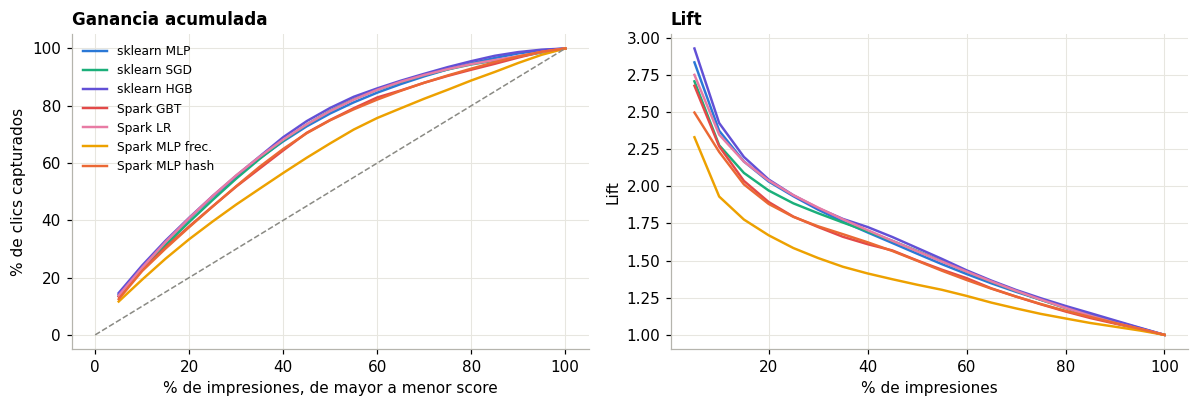

,sklearn MLP,sklearn SGD,sklearn HGB,Spark GBT,Spark LR,Spark MLP frec.,Spark MLP hash
Top 4 %,14.2,13.5,14.6,13.4,13.7,11.7,12.5
Top 9 %,23.7,22.8,24.3,22.7,23.5,19.3,22.3
Top 19 %,40.6,39.4,40.9,37.9,40.8,33.4,37.6
Top 29 %,55.3,54.6,55.6,51.8,55.7,45.5,51.9


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for k, c in cur.items():
    ax[0].plot(np.array(c["frac"]) * 100, np.array(c["gain"]) * 100, color=COL[k], lw=1.6, label=NOM[k])
    ax[1].plot(np.array(c["frac"]) * 100, c["lift"], color=COL[k], lw=1.6)
ax[0].plot([0, 100], [0, 100], color=C["gris"], ls="--", lw=1)
ax[0].set(title="Ganancia acumulada", xlabel="% de impresiones, de mayor a menor score", ylabel="% de clics capturados"); ax[0].legend(fontsize=8)
ax[1].set(title="Lift", xlabel="% de impresiones", ylabel="Lift"); plt.tight_layout(); plt.show()
pd.DataFrame({NOM[k]: {f"Top {int(f*100)} %": g * 100 for f, g in zip(c["frac"], c["gain"]) if round(f, 2) in (.05, .1, .2, .3)} for k, c in cur.items()}).round(1)

## 6.5 Inferencia estadística

DeLong compara AUC y McNemar compara aciertos con el umbral de validación, con corrección de Holm. Con 4,2 millones de
filas casi toda diferencia resulta significativa, de modo que importa también el tamaño del efecto.

In [7]:
d = pd.read_csv(ST / "delong.csv"); d["A"], d["B"] = d.a.map(NOM), d.c.map(NOM)
d[["A", "B", "auc_a", "auc_b", "dif", "z", "p_holm"]].round(5).sort_values("dif", key=abs).reset_index(drop=True)

,A,B,auc_a,auc_b,dif,z,p_holm
0,Spark GBT,Spark MLP hash,0.69842,0.69790,0.00052,2.77308,0.00555
1,sklearn MLP,Spark LR,0.72351,0.72545,-0.00194,-9.07719,0.00000
2,sklearn MLP,sklearn SGD,0.72351,0.72089,0.00262,11.56770,0.00000
3,sklearn SGD,Spark LR,0.72089,0.72545,-0.00457,-30.39376,0.00000
4,sklearn HGB,Spark LR,0.73336,0.72545,0.00791,43.81567,0.00000
5,sklearn MLP,sklearn HGB,0.72351,0.73336,-0.00985,-56.23472,0.00000
6,sklearn SGD,sklearn HGB,0.72089,0.73336,-0.01247,-63.85478,0.00000
7,sklearn SGD,Spark GBT,0.72089,0.69842,0.02247,96.45430,0.00000
8,sklearn SGD,Spark MLP hash,0.72089,0.69790,0.02299,103.32885,0.00000
9,sklearn MLP,Spark GBT,0.72351,0.69842,0.02509,96.85139,0.00000


In [8]:
m = pd.read_csv(ST / "mcnemar.csv"); m["A"], m["B"] = m.a.map(NOM), m.c.map(NOM)
m[["A", "B", "solo_a", "solo_b", "chi2", "p_holm"]].round(5).reset_index(drop=True)

,A,B,solo_a,solo_b,chi2,p_holm
0,sklearn MLP,sklearn SGD,482021,340883,24206.53292,0.00000
1,sklearn MLP,sklearn HGB,387424,240708,34268.73846,0.00000
2,sklearn MLP,Spark GBT,599972,336347,74224.29041,0.00000
3,sklearn MLP,Spark LR,414625,310961,14810.12253,0.00000
4,sklearn MLP,Spark MLP frec.,1154342,364729,410439.74281,0.00000
5,sklearn MLP,Spark MLP hash,491898,388404,12167.18927,0.00000
6,sklearn SGD,sklearn HGB,322714,317136,48.60972,0.00000
7,sklearn SGD,Spark GBT,430332,307845,20324.15016,0.00000
8,sklearn SGD,Spark LR,220586,258060,2933.74588,0.00000
9,sklearn SGD,Spark MLP frec.,959604,311129,330925.95272,0.00000


**Respuesta a P3: no.** El MLP de scikit-learn (AUC media 0,717) queda detrás de HGB con target encoding (0,733), de la regresión
logística de Spark con los 32,4 millones (0,7255) y de SGD (0,721). DeLong da todas las diferencias significativas tras Holm, con
la semilla de referencia. Es el resultado esperable con 4,2 millones de filas: la cifra que importa es la magnitud. Frente a HGB,
el MLP pierde 0,010 a 0,016 de AUC, lo bastante para mantenerse a lo largo de la curva de ganancia.

**El MLP es el más inestable y el peor calibrado de scikit-learn.** Su desviación entre semillas en la prueba es 0,0065, frente a
0,0009 de HGB, y su ECE de 0,029 es más del doble. Con la semilla 42 supera a SGD (0,7235 frente a 0,7209). En promedio, no.

**Dentro de Spark, la regresión logística supera a los dos MLP y a GBT.** El MLP con hash 2^9 y GBT empatan en AUC (0,698), y el
MLP con frecuencia y los datos completos es el peor modelo (0,639). Ese GBT usó 20 árboles por tiempo, y con 1 millón y 50 árboles
daba más en validación. No es una cota de lo que GBT puede hacer.

**La única diferencia no significativa en McNemar** es entre la LR de Spark y el MLP de Spark con hashing (p = 0,84 tras Holm). Con
sus umbrales aciertan casi las mismas filas, pese a la diferencia de AUC.